> 1. READ MUTATION DATA 

> 2. RANDOMFOREST MODEL

> 3. XGB MODEL

> 4. LGBM MODEL

> 1. READ MUTATION DATA (GOF, LOF)

In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import warnings
import re
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.model_selection import StratifiedGroupKFold

# 1. Load the perfectly balanced training datasets
# GOF total = 1400. LOF total = 1400.
gof_train = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/gof_train_1400.csv", index_col=0) # eve_score nan 31%
## gof_train['eve_score'].fillna(gof_train['eve_score'].mean(), inplace=True)
lof_train = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/lof_train_1400.csv", index_col=0) # eve_score nan 0%
neutral_train = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/neutral_train_2800.csv", index_col=0) # eve_score nan 0%
neutral_train['gene'] = neutral_train['new_hgnc_agg_ids'].str.split('_').str[0]  # Extract gene name from new_hgnc_agg_ids
# gof_lof concat
gof_lof_train = pd.concat([gof_train, lof_train], ignore_index=True) # 2800
# 2. Combine and Split 80/20 
gof_lof_train['gene'] = gof_lof_train['new_hgnc_agg_ids'].str.split('_').str[0]  # Extract gene name from new_hgnc_agg_ids

# Step-1 get equal distribution of GOF and LOF in the test set, while ensuring no gene overlap between train and test sets. Use StratifiedGroupKFold to achieve this.
####################################################################################################################################################################
X = gof_lof_train
y = gof_lof_train['goflof']
groups = gof_lof_train['gene']

overall_dist = y.value_counts(normalize=True)

best_seed = None
best_fold_idx = None
best_error = float('inf')

# Search across 100 seeds to find the split with minimum distribution error
for seed in range(100):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    
    for fold, (t_idx, v_idx) in enumerate(sgkf.split(X, y, groups)):
        test_dist = y.iloc[v_idx].value_counts(normalize=True)
        
        # Absolute difference across all 2 classes relative to overall 50/50 distribution
        error = (test_dist - overall_dist).abs().sum()
        
        if error < best_error:
            best_error = error
            best_seed = seed
            best_fold_idx = (t_idx, v_idx)

train_idx, test_idx = best_fold_idx
gof_loftrain_df = gof_lof_train.iloc[train_idx].reset_index(drop=True)
gof_loftrain_df['goflof'] = 1  # Make gof_loftrain_df into all Pathogenic (1)
gof_loftest_df = gof_lof_train.iloc[test_idx].reset_index(drop=True)
gof_loftest_df['goflof'] = 1  # Make gof_loftest_df into all Pathogenic (1)
print(f"Optimal Seed: {best_seed}")
print("\n--- Optimized Test Distribution ---")
print(gof_loftest_df['goflof'].value_counts(normalize=True).round(3))

# ---------------------------------------------------------
# Print Summary Statistics
# ---------------------------------------------------------

print("=== GENE COUNTS ===")
print(f"Train Unique Genes : {gof_loftrain_df['gene'].nunique()}")
print(f"Test Unique Genes  : {gof_loftest_df['gene'].nunique()}")

# Verify zero gene overlap
gene_overlap = set(gof_loftrain_df['gene']).intersection(set(gof_loftest_df['gene']))
print(f"Gene Overlap Count : {len(gene_overlap)}")

print("\n=== CLASS DISTRIBUTION (Variants) ===")
print("Train Class Counts:")
print(gof_loftrain_df['goflof'].value_counts())

print("\nTest Class Counts:")
print(gof_loftest_df['goflof'].value_counts())

print("\n=== CLASS PERCENTAGES ===")
print("Train Class Ratio (%):")
print((gof_loftrain_df['goflof'].value_counts(normalize=True) * 100).round(2))

print("\nTest Class Ratio (%):")
print((gof_loftest_df['goflof'].value_counts(normalize=True) * 100).round(2))


# Step-2: out of 2800 neutral variants, split 2378/422 into train and test sets, ensuring no gene overlap with the genes in gof_loftrain_df and gof_loftest_df datasets.
neutral_train_df = neutral_train[~neutral_train['gene'].isin(gof_loftest_df['gene'])]  # Remove genes present in gof_loftest_df 2381 
neutral_train_df['goflof'] = 0  # Make neutral_train_df into all Neutral (0)
neutral_test_df = neutral_train[~neutral_train['new_hgnc_agg_ids'].isin(neutral_train_df['new_hgnc_agg_ids'])]  # Keep only genes present in neutral_train_df 419
neutral_test_df['goflof'] = 0  # Make neutral_test_df into all Neutral (0)
# #########################################################################################################################
# 3 . Load validation datasets
gof_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/gof_val_325.csv", index_col=0) # eve_score nan 21%
## gof_val['eve_score'].fillna(gof_val['eve_score'].mean(), inplace=True)
lof_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/lof_val_325.csv", index_col=0) # eve_score nan 8%
gof_lof_val = pd.concat([gof_val, lof_val], ignore_index=True) # 650
gof_lof_val['goflof'] = 1  # Make gof_lof_val into all Pathogenic (1)
neutral_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/neutral_val_550.csv", index_col=0) # eve_score nan 0%
neutral_val['goflof'] = 0  # Make neutral_val into all Neutral (0)
##lof_val['eve_score'].fillna(lof_val['eve_score'].mean(), inplace=True)
# 4 . Combine validation datasets
test_val_df = pd.concat([gof_lof_val, neutral_val], ignore_index=True)
train_df = pd.concat([gof_loftrain_df, neutral_train_df], ignore_index=True) # 2378 + 2381 = 4759
test_df = pd.concat([gof_loftest_df, neutral_test_df], ignore_index=True) # 422 + 419 = 841

# 5. drop col [ 'Glycine-NATIVE-THRESHOLD', 'Glycine-MUTANT-THRESHOLD', 'Proline-MUTANT-THRESHOLD', 'Proline-NATIVE-THRESHOLD']
cols_drop = ['Glycine-NATIVE-THRESHOLD', 'Glycine-MUTANT-THRESHOLD', 'Proline-MUTANT-THRESHOLD', 'Proline-NATIVE-THRESHOLD', 'protein_len']
train_df.drop(columns=cols_drop, inplace=True)
test_df.drop(columns=cols_drop, inplace=True)
test_val_df.drop(columns=cols_drop, inplace=True)
# set new_hgnc_agg_ids as index for all three dataframes
train_df.set_index('new_hgnc_agg_ids', inplace=True)
test_df.set_index('new_hgnc_agg_ids', inplace=True)
test_val_df.set_index('new_hgnc_agg_ids', inplace=True)
# # drop gene from  train and test datasets
train_df.drop(columns=['gene'], inplace=True)   
test_df.drop(columns=['gene'], inplace=True)

Optimal Seed: 1

--- Optimized Test Distribution ---
goflof
1    1.0
Name: proportion, dtype: float64
=== GENE COUNTS ===
Train Unique Genes : 193
Test Unique Genes  : 50
Gene Overlap Count : 0

=== CLASS DISTRIBUTION (Variants) ===
Train Class Counts:
goflof
1    2378
Name: count, dtype: int64

Test Class Counts:
goflof
1    422
Name: count, dtype: int64

=== CLASS PERCENTAGES ===
Train Class Ratio (%):
goflof
1    100.0
Name: proportion, dtype: float64

Test Class Ratio (%):
goflof
1    100.0
Name: proportion, dtype: float64


/var/folders/h0/49pf4hv97sdg37fww258kmrc0000gq/T/ipykernel_3472/2173537428.py:88: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  neutral_train_df['goflof'] = 0  # Make neutral_train_df into all Neutral (0)
/var/folders/h0/49pf4hv97sdg37fww258kmrc0000gq/T/ipykernel_3472/2173537428.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  neutral_test_df['goflof'] = 0  # Make neutral_test_df into all Neutral (0)


In [2]:
# Clean XGBoost's forbidden characters from column names
def clean_cols(df):
    new_cols = []
    for col in df.columns:
        c = col.strip()
        c = re.sub(r'[\[\]<>]', '_', c)
        new_cols.append(c)
    df.columns = new_cols
    return df

train_df = clean_cols(train_df)
test_df = clean_cols(test_df)
test_val_df = clean_cols(test_val_df)
print(f"Train shape: {train_df.shape}, Test shape: {test_df.shape}, Validation shape: {test_val_df.shape}")



Train shape: (4759, 61), Test shape: (841, 61), Validation shape: (1200, 61)


In [3]:
# Feature Engineering: 

def feature_engineering(df):
    df = df.copy()
    
    # 1. Surface accessibility and rigidity interactions
    df['buried'] = (df['rsa'] < 0.15).astype(float)
    df['exposed'] = (df['rsa'] > 0.45).astype(float)
    df['rigid'] = (df['plddt_score'] > 85).astype(float)
    df['flexible'] = (df['plddt_score'] < 60).astype(float)
    df['disordered'] = (df['disorder'] > 0.5).astype(float)
    
    df['exposed_flexible'] = df['exposed'] * df['flexible']
    df['buried_rigid'] = df['buried'] * df['rigid']
    # df['small_protein'] = (df['protein_len'] < 300).astype(float)
    # df['small_protein_buried'] = df['small_protein'] * df['buried']
    
    # 2. Charge and Hydrophobicity changes
    df['charge_change'] = df['BuriedCharge-MUTANT-CHARGE'] - df['BuriedCharge-NATIVE-CHARGE']
    df['abs_charge_change'] = df['charge_change'].abs()
    df['hphob_change_core'] = df['CorePhilic-MUTANT-HPHOB'] - df['CorePhilic-NATIVE-HPHOB']
    df['abs_hphob_change_core'] = df['hphob_change_core'].abs()
    df['hphob_change_surf'] = df['SurfacePhobic-MUTANT-HPHOB'] - df['SurfacePhobic-NATIVE-HPHOB']
    df['abs_hphob_change_surf'] = df['hphob_change_surf'].abs()
    # df['charge_disruption_density'] = df['abs_charge_change'] / np.log1p(df['protein_len'])
    
    # 3. Energy differences
    df['glycine_energy_change'] = df['Glycine-MUTANT-ENERGY'] - df['Glycine-NATIVE-ENERGY']
    df['proline_energy_change'] = df['Proline-MUTANT-ENERGY'] - df['Proline-NATIVE-ENERGY']
    
    # 4. Ratios and products
    df['rsa_x_asa'] = df['rsa'] * df['asa']
    df['rsa_x_plddt'] = df['rsa'] * df['plddt_score']
    df['disorder_x_plddt'] = df['disorder'] * df['plddt_score']
    
    # 5. Non-linear AlphaMissense features
    df['am_pathogenicity_sq'] = df['am_pathogenicity'] ** 2
    
    # 6. Interaction with energies
    df['clash_x_buried'] = df['Clash-ENERGY'] * df['buried']
    df['hbonds_x_buried'] = df['HBonds-ENERGY'] * df['buried']
    
    # 7. Conformation disruptions
    df['glycine_disruption'] = df['Glycine-BOOL'] * df['Glycine-MUTANT-ENERGY']
    df['proline_disruption'] = df['Proline-BOOL'] * df['Proline-MUTANT-ENERGY']
    
    return df

print("Applying feature engineering...")
train_df = feature_engineering(train_df) # 83 features after engineering
test_df = feature_engineering(test_df)
test_val_df = feature_engineering(test_val_df)

Applying feature engineering...


In [4]:
# count the number of 0s and 1s in the goflof column
from sklearn.preprocessing import StandardScaler
print(train_df['goflof'].value_counts())
X = train_df.drop(['goflof'], axis = 1)
y = train_df['goflof']

X_train = X # 
X_test = test_df.drop(['goflof'], axis=1) #
Y_train = y
Y_test = test_df['goflof']

goflof
0    2381
1    2378
Name: count, dtype: int64


> 2. RANDOMFOREST MODEL

Random Forest Model training

Running RFECV for feature selection...
RF optimal features: 76 → ['mutation', 'WT_aa', 'BuriedCharge-RELACCESS', 'BuriedCharge-NATIVE-CHARGE', 'BuriedCharge-BOOL', 'BuriedCharge-MUTANT-CHARGE', 'CisPro-OMEGA', 'CisPro-BOOL', 'Clash-ENERGY', 'Clash-BOOL', 'CorePhilic-RELACCESS', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-BOOL', 'CorePhilic-MUTANT-HPHOB', 'Glycine-MUTANT-ENERGY', 'Glycine-NATIVE-ENERGY', 'Glycine-PHI', 'Glycine-PSI', 'Glycine-NATIVE-BOOL', 'HBonds-ZVAL', 'HBonds-PARTNER-RES', 'HBonds-BOOL', 'HBonds-ENERGY', 'Proline-NATIVE-ENERGY', 'Proline-PHI', 'Proline-MUTANT-ENERGY', 'Proline-PSI', 'SSGeom-BOOL', 'SurfacePhobic-MUTANT-HPHOB', 'SurfacePhobic-RELACCESS', 'SurfacePhobic-NATIVE-HPHOB', 'SurfacePhobic-BOOL', 'plddt_score', 'rsa', 'asa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'phi', 'psi', 'disorder', 'am_pathogenicity', 'phosphorylation', 'methylation', 'ubiquitination', 'acetylation', 'sumoylation', 'pro_domain_num', 'mutation_region_num', 'self_PPI', 'non_self_PPI', 'conservation

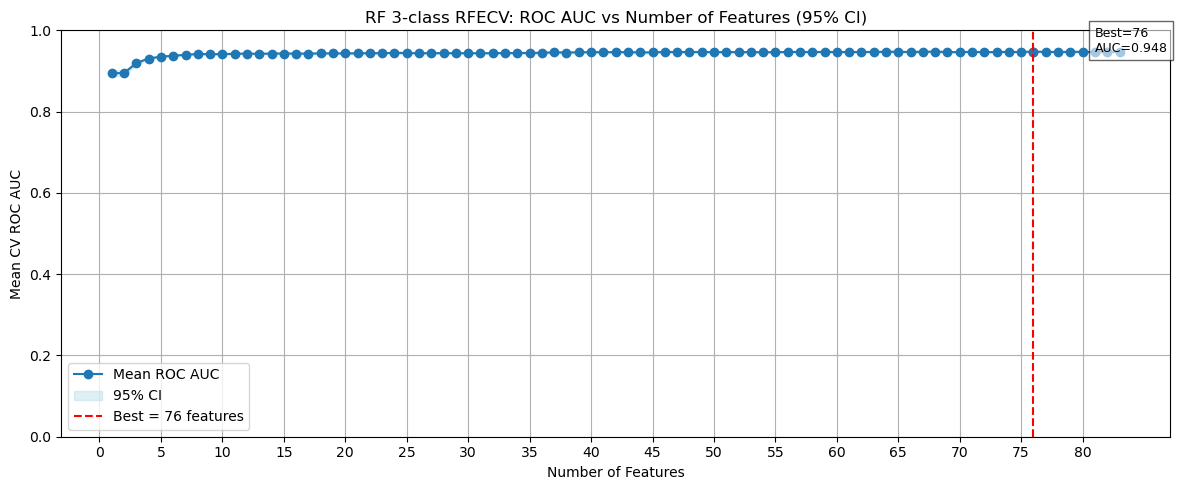

Best Parameters : {'max_depth': None, 'n_estimators': 300}
Best CV ROC AUC : 0.947
Train ROC AUC   : 1.000

Calibrated prob range: [0.021, 1.000]
Mean prob (should be ~0.5): 0.510

Optimal threshold (Youden J on TEST set, calibrated): 0.5392
  Sensitivity (Pathogenic recall) : 0.867
  Specificity (Neutral recall) : 0.885


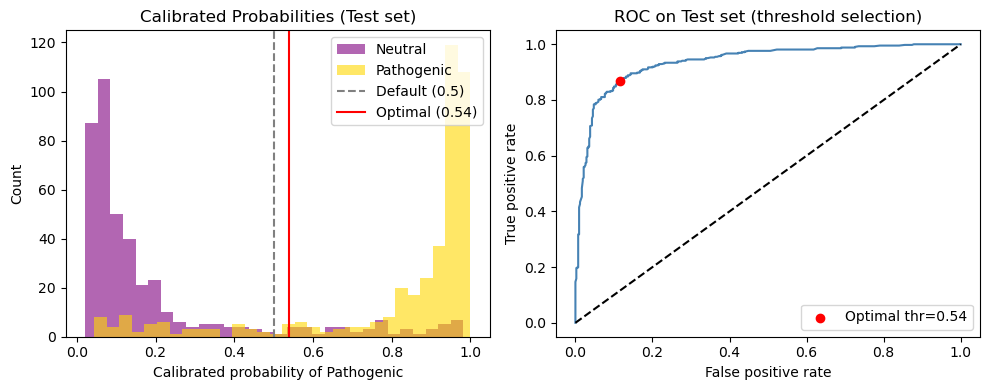


--- Test Set: Default threshold (0.5) ---


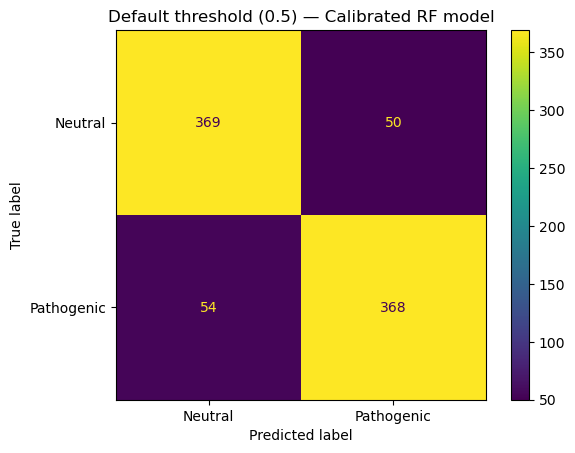

              precision    recall  f1-score   support

     Neutral       0.87      0.88      0.88       419
  Pathogenic       0.88      0.87      0.88       422

    accuracy                           0.88       841
   macro avg       0.88      0.88      0.88       841
weighted avg       0.88      0.88      0.88       841


--- Test Set: Optimal threshold (0.539) ---


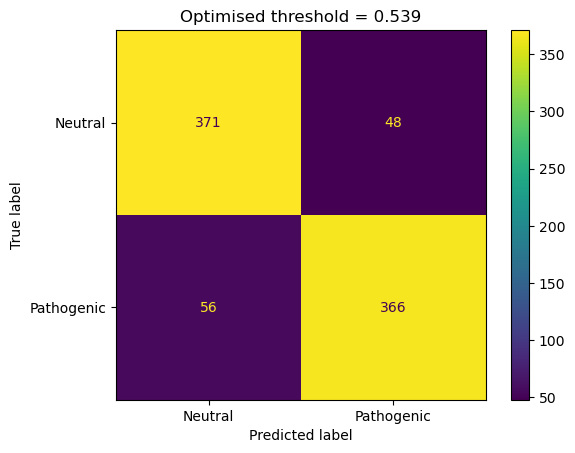

              precision    recall  f1-score   support

     Neutral       0.87      0.89      0.88       419
  Pathogenic       0.88      0.87      0.88       422

    accuracy                           0.88       841
   macro avg       0.88      0.88      0.88       841
weighted avg       0.88      0.88      0.88       841


★ RF Validation AUC (calibrated): 0.8162


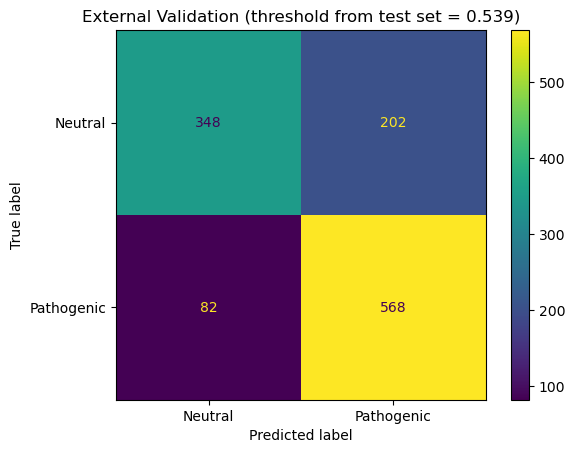

              precision    recall  f1-score   support

     Neutral       0.81      0.63      0.71       550
  Pathogenic       0.74      0.87      0.80       650

    accuracy                           0.76      1200
   macro avg       0.77      0.75      0.76      1200
weighted avg       0.77      0.76      0.76      1200


CV AUC: 0.946 ± 0.003


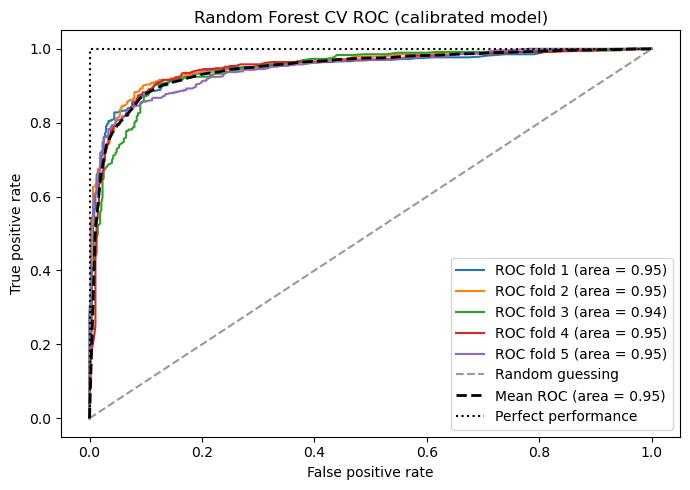

cv ROC AUC   : 0.934 ± 0.035
cv precision : 0.882 ± 0.043
cv recall    : 0.881 ± 0.044
cv f1        : 0.881 ± 0.045


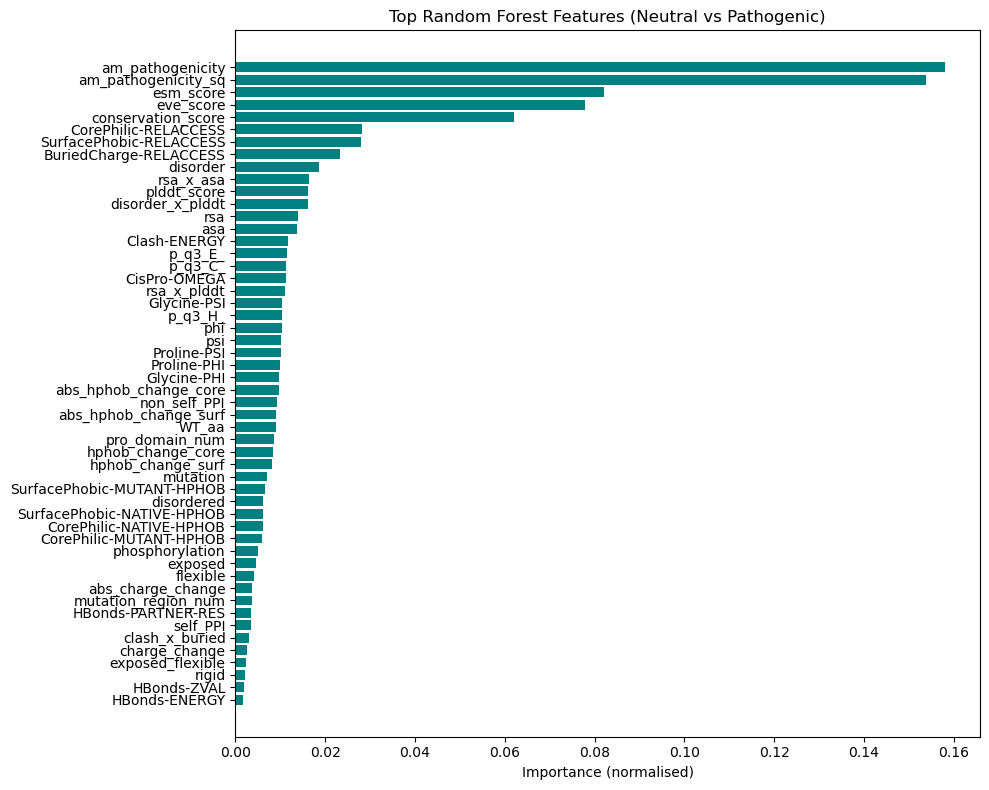


Top features:
                Feature  Importance
       am_pathogenicity    0.157921
    am_pathogenicity_sq    0.153701
              esm_score    0.082028
              eve_score    0.077786
     conservation_score    0.062024
   CorePhilic-RELACCESS    0.028310
SurfacePhobic-RELACCESS    0.027981
 BuriedCharge-RELACCESS    0.023194
               disorder    0.018528
              rsa_x_asa    0.016383


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_selection import RFECV
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split

AUC, AUC_sd, AC, AC_sd, Pre, Pre_sd, Re, Re_sd, f1, f1_sd, Best1, Best2 = ([] for _ in range(12))


# ── 2. RFECV Feature Selection ────────────────────────────────────────────────
print("Running RFECV for feature selection...")
rf_rfe    = RandomForestClassifier(n_estimators=300, random_state=42)
rfecv_rf  = RFECV(
    estimator=rf_rfe,
    step=1,
    min_features_to_select=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc",           #
    n_jobs=-1,
)
rfecv_rf.fit(X_train, Y_train)

rf_features      = list(rfecv_rf.get_feature_names_out())
X_train_selected = X_train[rf_features]
X_test_selected  = X_test[rf_features]
print(f"RF optimal features: {rfecv_rf.n_features_} → {rf_features}")

# Plot RFECV curve with 95% CI
n_features  = len(rfecv_rf.cv_results_["mean_test_score"])
mean_scores = rfecv_rf.cv_results_["mean_test_score"]
std_scores  = rfecv_rf.cv_results_["std_test_score"]
ci          = 1.96 * (std_scores / np.sqrt(5))
x_range     = range(1, n_features + 1)
best_idx    = np.argmax(mean_scores)

plt.figure(figsize=(12, 5))
plt.plot(x_range, mean_scores, marker='o', label='Mean ROC AUC')
plt.fill_between(x_range, mean_scores - ci, mean_scores + ci,
                 color='lightblue', alpha=0.4, label='95% CI')
plt.axvline(best_idx + 1, color='red', linestyle='--',
            label=f'Best = {best_idx + 1} features')
plt.scatter(best_idx + 1, mean_scores[best_idx], color='red')
plt.text(best_idx + 1 + 5, mean_scores[best_idx],
         f'Best={best_idx+1}\nAUC={mean_scores[best_idx]:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))
plt.xlabel("Number of Features"); plt.ylabel("Mean CV ROC AUC")
plt.title("RF 3-class RFECV: ROC AUC vs Number of Features (95% CI)")
plt.xticks(np.arange(0, n_features + 1, step=5))
plt.ylim(0, 1)
plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig("RF_3class_RFECV_feature_selection.png", dpi=600)
plt.show()

# ── 3. GridSearchCV for hyperparameter tuning ─────────────────────────────────
param_grid = {
    'n_estimators': [10, 20, 30, 50, 100, 200, 300],
    'max_depth':    [1, 2, 3, 10, None]
}
gs = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='roc_auc',           # changed from accuracy → roc_auc
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    refit=True, n_jobs=-1, return_train_score=True
)
gs.fit(X_train_selected, Y_train)

best_params = gs.best_params_
print(f"Best Parameters : {best_params}")
print(f"Best CV ROC AUC : {gs.best_score_:.3f}")
print(f"Train ROC AUC   : {gs.cv_results_['mean_train_score'][gs.best_index_]:.3f}")

# ── 4. Calibrate probabilities ────────────────────────────────────────────────
# Random Forest probabilities are often poorly calibrated (overly confident)
# Isotonic regression corrects this
raw_model = RandomForestClassifier(**best_params, random_state=42)
calibrated_model_rf = CalibratedClassifierCV(raw_model, method='isotonic', cv=5)
calibrated_model_rf.fit(X_train_selected, Y_train)

proba_test_cal = calibrated_model_rf.predict_proba(X_test_selected)[:, 1]
print(f"\nCalibrated prob range: [{proba_test_cal.min():.3f}, {proba_test_cal.max():.3f}]")
print(f"Mean prob (should be ~0.5): {proba_test_cal.mean():.3f}")

# ── 5. Optimal threshold on TEST set (Youden-J) ───────────────────────────────
fpr_t, tpr_t, thr_t = roc_curve(Y_test, proba_test_cal, pos_label=1)
j_idx    = np.argmax(tpr_t - fpr_t)
best_thr = thr_t[j_idx]
print(f"\nOptimal threshold (Youden J on TEST set, calibrated): {best_thr:.4f}")
print(f"  Sensitivity (Pathogenic recall) : {tpr_t[j_idx]:.3f}")
print(f"  Specificity (Neutral recall) : {1 - fpr_t[j_idx]:.3f}")

# ── 6. Probability distribution plot (sanity check) ──────────────────────────
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(proba_test_cal[Y_test == 0], bins=30, alpha=0.6, label='Neutral', color='purple')
plt.hist(proba_test_cal[Y_test == 1], bins=30, alpha=0.6, label='Pathogenic', color='gold')
plt.axvline(0.5,      color='gray', linestyle='--', label='Default (0.5)')
plt.axvline(best_thr, color='red',  linestyle='-',  label=f'Optimal ({best_thr:.2f})')
plt.xlabel('Calibrated probability of Pathogenic')
plt.ylabel('Count')
plt.title('Calibrated Probabilities (Test set)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fpr_t, tpr_t, color='steelblue')
plt.scatter(fpr_t[j_idx], tpr_t[j_idx], color='red', zorder=5,
            label=f'Optimal thr={best_thr:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC on Test set (threshold selection)')
plt.legend()
plt.tight_layout()
plt.savefig("RF_calibrated_threshold_analysis.png", dpi=600)
plt.show()

# ── 7. Test set: Default threshold (0.5) ─────────────────────────────────────
print("\n--- Test Set: Default threshold (0.5) ---")
y_pred_default = (proba_test_cal >= 0.5).astype(int)
cm_def = confusion_matrix(Y_test, y_pred_default)
ConfusionMatrixDisplay(cm_def, display_labels=['Neutral', 'Pathogenic']).plot(cmap='viridis')
plt.title("Default threshold (0.5) — Calibrated RF model")
plt.savefig("RF_bestModel_ConfusionMatrix_default_miRNA_HG.png", dpi=600)
plt.savefig("RF_bestModel_ConfusionMatrix_default_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(Y_test, y_pred_default, target_names=['Neutral', 'Pathogenic']))

# ── 8. Test set: Optimal (Youden-J) threshold ────────────────────────────────
print(f"\n--- Test Set: Optimal threshold ({best_thr:.3f}) ---")
y_pred_opt = (proba_test_cal >= best_thr).astype(int)
cm_opt = confusion_matrix(Y_test, y_pred_opt)
ConfusionMatrixDisplay(cm_opt, display_labels=['Neutral', 'Pathogenic']).plot(cmap='viridis')
plt.title(f"Optimised threshold = {best_thr:.3f}")
plt.savefig("RF_bestModel_ConfusionMatrix_OptThr_miRNA_HG.png", dpi=600)
plt.savefig("RF_bestModel_ConfusionMatrix_OptThr_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(Y_test, y_pred_opt, target_names=['Neutral', 'Pathogenic']))

# ── 9. External Validation (BLIND — threshold fixed from test set) ────────────
rf_val_fresh = test_val_df.copy()  # already preprocessed and ready for RF

target_rf  = rf_val_fresh['goflof']
X_val_rf   = rf_val_fresh[rf_features]
proba_val_cal = calibrated_model_rf.predict_proba(X_val_rf)[:, 1]

# AUC on external validation
auc_rf_val = roc_auc_score(target_rf, proba_val_cal)
print(f"\n★ RF Validation AUC (calibrated): {auc_rf_val:.4f}")

# Apply threshold from test set — no leakage from validation
y_pred_val = (proba_val_cal >= best_thr).astype(int)
cm_val = confusion_matrix(target_rf, y_pred_val)
ConfusionMatrixDisplay(cm_val, display_labels=['Neutral', 'Pathogenic']).plot(cmap='viridis')
plt.title(f"External Validation (threshold from test set = {best_thr:.3f})")
plt.savefig("RF_bestModel_ConfusionMatrix_validation.png", dpi=600)
plt.savefig("RF_bestModel_ConfusionMatrix_validation.svg", dpi=600)
plt.show()
print(classification_report(target_rf, y_pred_val, target_names=['Neutral', 'Pathogenic']))

# ── 10. CV ROC folds ──────────────────────────────────────────────────────────
cv_outer = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train_selected, Y_train))
mean_tpr = np.zeros(100)
mean_fpr = np.linspace(0, 1, 100)
sd_list  = []

plt.figure(figsize=(7, 5))
for i, (tr, te) in enumerate(cv_outer):
    fold_model = RandomForestClassifier(**best_params, random_state=42)
    fold_model.fit(X_train_selected.iloc[tr], Y_train.iloc[tr])
    probas      = fold_model.predict_proba(X_train_selected.iloc[te])
    fpr, tpr, _ = roc_curve(Y_train.iloc[te], probas[:, 1], pos_label=1)
    mean_tpr   += np.interp(mean_fpr, fpr, tpr)
    fold_auc    = auc(fpr, tpr)
    sd_list.append(fold_auc)
    plt.plot(fpr, tpr, label=f'ROC fold {i+1} (area = {fold_auc:.2f})')

mean_tpr /= len(cv_outer)
mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
mean_sd  = np.std(sd_list)
print(f"\nCV AUC: {mean_auc:.3f} ± {mean_sd:.3f}")

plt.plot([0, 1],    [0, 1],    linestyle='--', color=(.6,.6,.6), label='Random guessing')
plt.plot(mean_fpr,  mean_tpr,  'k--', lw=2,   label=f'Mean ROC (area = {mean_auc:.2f})')
plt.plot([0, 0, 1], [0, 1, 1], linestyle=':',  color='black',   label='Perfect performance')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Random Forest CV ROC (calibrated model)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("RF_bestModel_AUC_miRNA_HG.png", dpi=600)
plt.savefig("RF_bestModel_AUC_miRNA_HG.svg", dpi=600)
plt.show()

AUC.append(mean_auc)
AUC_sd.append(mean_sd)

# ── 11. CV metrics ────────────────────────────────────────────────────────────
fresh_rf = RandomForestClassifier(**best_params, random_state=42)
scores1  = cross_val_score(fresh_rf, X_train_selected, Y_train, scoring='roc_auc', cv=5)
scores2  = cross_val_score(fresh_rf, X_train_selected, Y_train,
                           scoring=make_scorer(precision_score, average='macro'), cv=5)
scores3  = cross_val_score(fresh_rf, X_train_selected, Y_train,
                           scoring=make_scorer(recall_score,    average='macro'), cv=5)
scores4  = cross_val_score(fresh_rf, X_train_selected, Y_train,
                           scoring=make_scorer(f1_score,        average='macro'), cv=5)

print(f"cv ROC AUC   : {np.mean(scores1):.3f} ± {np.std(scores1):.3f}")
print(f"cv precision : {np.mean(scores2):.3f} ± {np.std(scores2):.3f}")
print(f"cv recall    : {np.mean(scores3):.3f} ± {np.std(scores3):.3f}")
print(f"cv f1        : {np.mean(scores4):.3f} ± {np.std(scores4):.3f}")

AC.append(np.mean(scores1));  AC_sd.append(np.std(scores1))
Pre.append(np.mean(scores2)); Pre_sd.append(np.std(scores2))
Re.append(np.mean(scores3));  Re_sd.append(np.std(scores3))
f1.append(np.mean(scores4));  f1_sd.append(np.std(scores4))
Best1.append(best_params['n_estimators'])
Best2.append(best_params['max_depth'])

# ── 12. Feature importance (averaged across calibrated folds) ─────────────────
importances_list = []
for calibrated_clf in calibrated_model_rf.calibrated_classifiers_:
    importances_list.append(calibrated_clf.estimator.feature_importances_)

importances = np.mean(importances_list, axis=0)
importances = importances / importances.sum()   # normalise to 0–1

feature_importance_df = pd.DataFrame({'Feature': X_train_selected.columns, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

n_top = min(52, len(feature_importance_df))
plt.figure(figsize=(10, 8))
plt.barh(
    feature_importance_df['Feature'][:n_top][::-1],
    feature_importance_df['Importance'][:n_top][::-1],
    color='teal'
)
plt.xlabel('Importance (normalised)')
plt.title('Top Random Forest Features (Neutral vs Pathogenic)')
plt.tight_layout()
plt.savefig("RF_bestModel_FeatureImportance_miRNA_HG.png", dpi=600)
plt.show()

print("\nTop features:")
print(feature_importance_df.head(10).to_string(index=False))

# save model and feature importance to CSV
import joblib
joblib.dump(calibrated_model_rf, "RF_pathogenicity.pkl")
feature_importance_df.to_csv("RF_pathogenicity-features.csv", index=False)

> 3. XGB MODEL

XGB RFECV optimal features: 53 → ['mutation', 'WT_aa', 'BuriedCharge-RELACCESS', 'BuriedCharge-NATIVE-CHARGE', 'BuriedCharge-BOOL', 'CisPro-OMEGA', 'Clash-ENERGY', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-BOOL', 'CorePhilic-MUTANT-HPHOB', 'Glycine-MUTANT-ENERGY', 'Glycine-NATIVE-ENERGY', 'Glycine-PHI', 'Glycine-PSI', 'HBonds-ZVAL', 'HBonds-PARTNER-RES', 'HBonds-BOOL', 'HBonds-ENERGY', 'Proline-NATIVE-ENERGY', 'Proline-MUTANT-ENERGY', 'SurfacePhobic-BOOL', 'plddt_score', 'rsa', 'asa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'phi', 'psi', 'disorder', 'am_pathogenicity', 'phosphorylation', 'ubiquitination', 'pro_domain_num', 'mutation_region_num', 'self_PPI', 'non_self_PPI', 'conservation_score', 'esm_score', 'eve_score', 'exposed_flexible', 'buried_rigid', 'charge_change', 'abs_charge_change', 'hphob_change_core', 'abs_hphob_change_core', 'glycine_energy_change', 'proline_energy_change', 'rsa_x_asa', 'rsa_x_plddt', 'disorder_x_plddt', 'clash_x_buried', 'hbonds_x_buried']


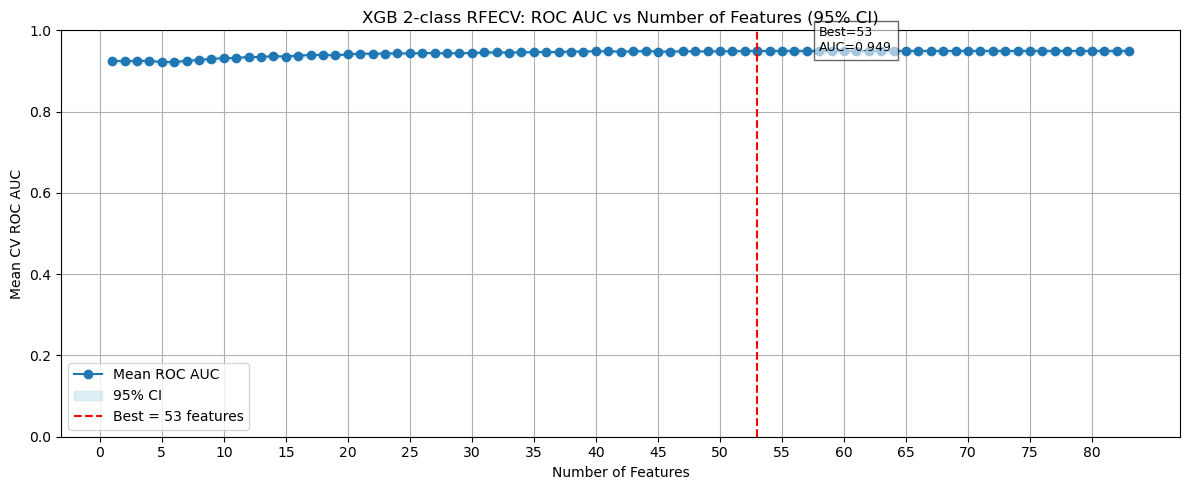

/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Parameters : {'learning_rate': 0.1, 'max_depth': 15, 'n_estimators': 300}
Best CV ROC AUC : 0.951
Train ROC AUC   : 1.000

Calibrated prob range: [0.000, 1.000]
Mean prob (should be ~0.5): 0.506

Optimal threshold (Youden J on TEST set, calibrated): 0.4526
  Sensitivity (Pathogenic recall) : 0.870
  Specificity (Neutral recall) : 0.878


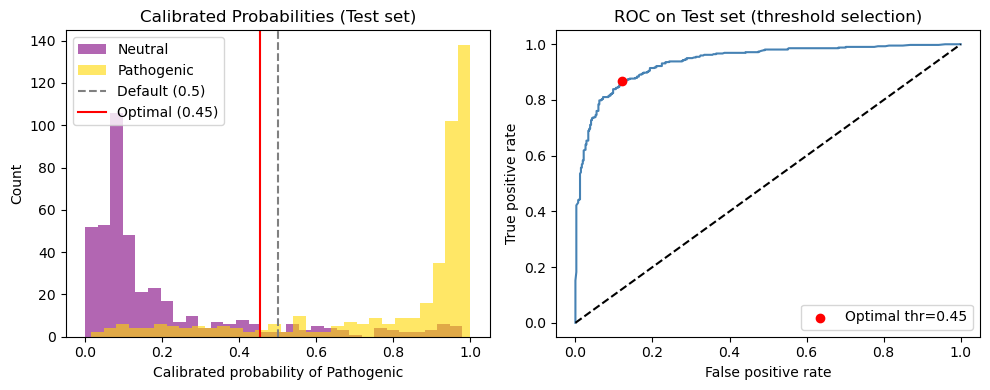


--- Test Set: Default threshold (0.5) ---


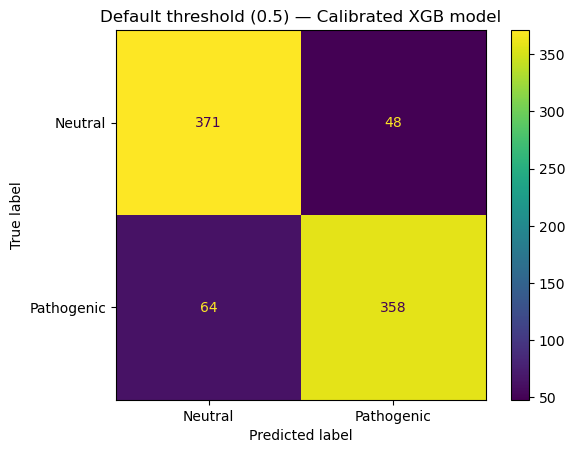

              precision    recall  f1-score   support

     Neutral       0.85      0.89      0.87       419
  Pathogenic       0.88      0.85      0.86       422

    accuracy                           0.87       841
   macro avg       0.87      0.87      0.87       841
weighted avg       0.87      0.87      0.87       841


--- Test Set: Optimal threshold (0.453) ---


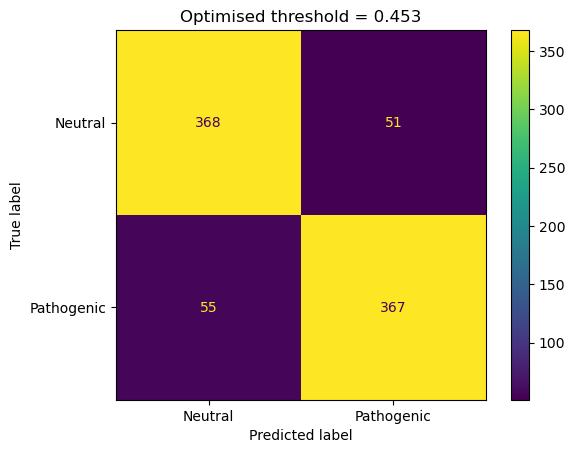

              precision    recall  f1-score   support

     Neutral       0.87      0.88      0.87       419
  Pathogenic       0.88      0.87      0.87       422

    accuracy                           0.87       841
   macro avg       0.87      0.87      0.87       841
weighted avg       0.87      0.87      0.87       841


★ XGBoost Validation AUC (calibrated): 0.8182


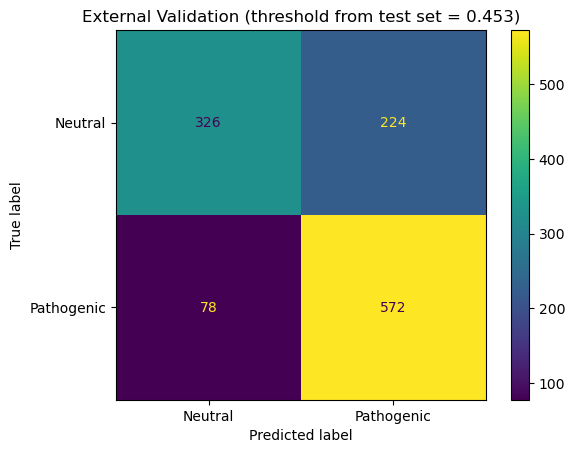

              precision    recall  f1-score   support

     Neutral       0.81      0.59      0.68       550
  Pathogenic       0.72      0.88      0.79       650

    accuracy                           0.75      1200
   macro avg       0.76      0.74      0.74      1200
weighted avg       0.76      0.75      0.74      1200


CV AUC: 0.949 ± 0.004


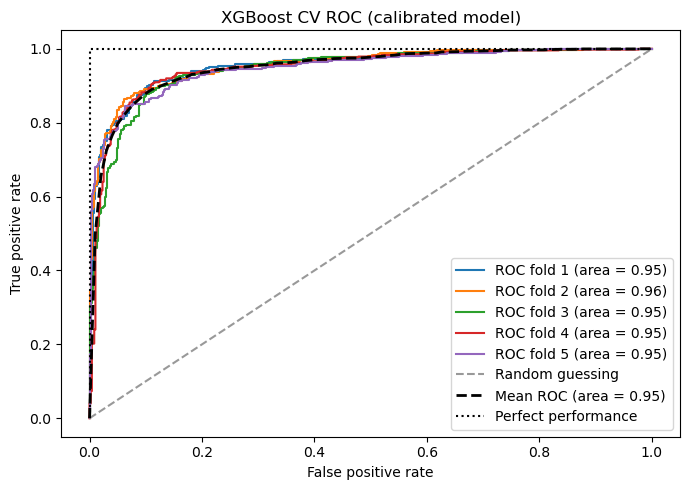

cv ROC AUC   : 0.932 ± 0.042
cv precision : 0.873 ± 0.044
cv recall    : 0.873 ± 0.045
cv f1        : 0.873 ± 0.045


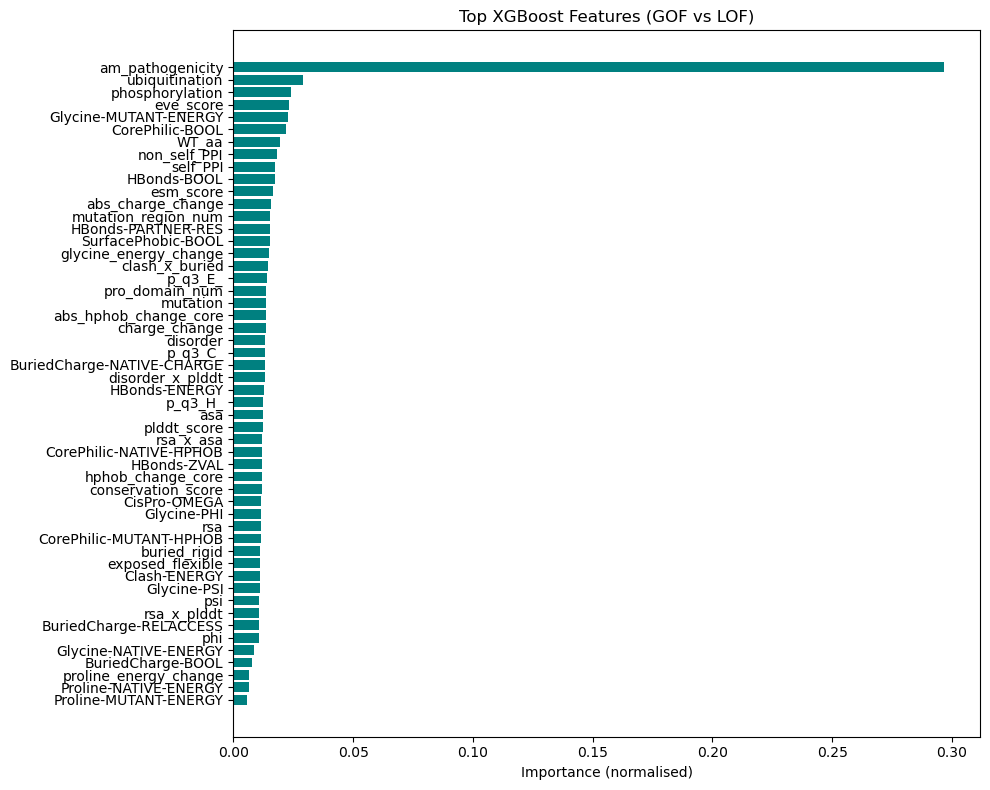


Top 10 features:
              Feature  Importance
     am_pathogenicity    0.296818
       ubiquitination    0.029093
      phosphorylation    0.024011
            eve_score    0.023312
Glycine-MUTANT-ENERGY    0.023005
      CorePhilic-BOOL    0.021809
                WT_aa    0.019317
         non_self_PPI    0.018090
             self_PPI    0.017569
          HBonds-BOOL    0.017359


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xgboost as xgb
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split

AUC, AUC_sd, AC, AC_sd, Pre, Pre_sd, Re, Re_sd, f1, f1_sd, Best1, Best2 = ([] for _ in range(12))


# ── 2. Feature selection (from RFECV) ────────────────────────────────────────
xgb_rfe = xgb.XGBClassifier(n_estimators=300, random_state=42)
rfecv_xgb = RFECV(
    estimator=xgb_rfe,
    step=1,
    min_features_to_select=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc",
    n_jobs=-1,
)
rfecv_xgb.fit(X_train, Y_train) 
xgb_features      = list(rfecv_xgb.get_feature_names_out())
X_train_selected = X_train[xgb_features]
X_test_selected  = X_test[xgb_features]
print(f"XGB RFECV optimal features: {rfecv_xgb.n_features_} → {xgb_features}")  
#plot RFECV curve with 95% CI
n_features  = len(rfecv_xgb.cv_results_["mean_test_score"])
mean_scores = rfecv_xgb.cv_results_["mean_test_score"]
std_scores  = rfecv_xgb.cv_results_["std_test_score"]
ci          = 1.96 * (std_scores / np.sqrt(5))
x_range     = range(1, n_features + 1)
best_idx    = np.argmax(mean_scores)    
plt.figure(figsize=(12, 5))
plt.plot(x_range, mean_scores, marker='o', label='Mean ROC AUC')
plt.fill_between(x_range, mean_scores - ci, mean_scores + ci,
                 color='lightblue', alpha=0.4, label='95% CI')
plt.axvline(best_idx + 1, color='red', linestyle='--',
            label=f'Best = {best_idx + 1} features')
plt.scatter(best_idx + 1, mean_scores[best_idx], color='red')
plt.text(best_idx + 1 + 5, mean_scores[best_idx],
         f'Best={best_idx+1}\nAUC={mean_scores[best_idx]:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))
plt.xlabel("Number of Features"); plt.ylabel("Mean CV ROC AUC")
plt.title("XGB 2-class RFECV: ROC AUC vs Number of Features (95% CI)")
plt.xticks(np.arange(0, n_features + 1, step=5))
plt.ylim(0, 1)
plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig("XGB_2class_RFECV_feature_selection.png", dpi=600)
plt.show()

# ── 3. GridSearchCV for hyperparameter tuning ─────────────────────────────────
param_grid = {
    'n_estimators':  [10, 20, 30, 50, 100, 200, 300, 350, 400],
    'max_depth':     [1, 3, 5, 7, 9, 15],
    'learning_rate': [0.01, 0.1, 0.2, 0.21]
}
gs = GridSearchCV(
    estimator=xgb.XGBClassifier(eval_metric='logloss', random_state=42),
    param_grid=param_grid,
    scoring='roc_auc',           # changed from accuracy → roc_auc
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    refit=True, n_jobs=-1, return_train_score=True
)
gs.fit(X_train_selected, Y_train)

best_params = gs.best_params_
print(f"Best Parameters : {best_params}")
print(f"Best CV ROC AUC : {gs.best_score_:.3f}")
print(f"Train ROC AUC   : {gs.cv_results_['mean_train_score'][gs.best_index_]:.3f}")

# ── 4. Calibrate probabilities ────────────────────────────────────────────────
raw_model_xgb = xgb.XGBClassifier(**best_params, eval_metric='logloss', random_state=42)
calibrated_model_xgb = CalibratedClassifierCV(raw_model_xgb, method='isotonic', cv=5)
calibrated_model_xgb.fit(X_train_selected, Y_train)

proba_test_cal = calibrated_model_xgb.predict_proba(X_test_selected)[:, 1]
print(f"\nCalibrated prob range: [{proba_test_cal.min():.3f}, {proba_test_cal.max():.3f}]")
print(f"Mean prob (should be ~0.5): {proba_test_cal.mean():.3f}")

# ── 5. Optimal threshold on TEST set (Youden-J) ───────────────────────────────
fpr_t, tpr_t, thr_t = roc_curve(Y_test, proba_test_cal, pos_label=1)
j_idx    = np.argmax(tpr_t - fpr_t)
best_thr = thr_t[j_idx]
print(f"\nOptimal threshold (Youden J on TEST set, calibrated): {best_thr:.4f}")
print(f"  Sensitivity (Pathogenic recall) : {tpr_t[j_idx]:.3f}")
print(f"  Specificity (Neutral recall) : {1 - fpr_t[j_idx]:.3f}")

# ── 6. Probability distribution plot (sanity check) ──────────────────────────
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(proba_test_cal[Y_test == 0], bins=30, alpha=0.6, label='Neutral', color='purple')
plt.hist(proba_test_cal[Y_test == 1], bins=30, alpha=0.6, label='Pathogenic', color='gold')
plt.axvline(0.5,      color='gray', linestyle='--', label='Default (0.5)')
plt.axvline(best_thr, color='red',  linestyle='-',  label=f'Optimal ({best_thr:.2f})')
plt.xlabel('Calibrated probability of Pathogenic')
plt.ylabel('Count')
plt.title('Calibrated Probabilities (Test set)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fpr_t, tpr_t, color='steelblue')
plt.scatter(fpr_t[j_idx], tpr_t[j_idx], color='red', zorder=5,
            label=f'Optimal thr={best_thr:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC on Test set (threshold selection)')
plt.legend()
plt.tight_layout()
plt.savefig("xgb_calibrated_threshold_analysis.png", dpi=600)
plt.show()

# ── 7. Test set: Default threshold (0.5) ─────────────────────────────────────
print("\n--- Test Set: Default threshold (0.5) ---")
y_pred_default = (proba_test_cal >= 0.5).astype(int)
cm_def = confusion_matrix(Y_test, y_pred_default)
ConfusionMatrixDisplay(cm_def, display_labels=['Neutral', 'Pathogenic']).plot(cmap='viridis')
plt.title("Default threshold (0.5) — Calibrated XGB model")
plt.savefig("xgb_bestModel_ConfusionMatrix_default_miRNA_HG.png", dpi=600)
plt.savefig("xgb_bestModel_ConfusionMatrix_default_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(Y_test, y_pred_default, target_names=['Neutral', 'Pathogenic']))

# ── 8. Test set: Optimal (Youden-J) threshold ────────────────────────────────
print(f"\n--- Test Set: Optimal threshold ({best_thr:.3f}) ---")
y_pred_opt = (proba_test_cal >= best_thr).astype(int)
cm_opt = confusion_matrix(Y_test, y_pred_opt)
ConfusionMatrixDisplay(cm_opt, display_labels=['Neutral', 'Pathogenic']).plot(cmap='viridis')
plt.title(f"Optimised threshold = {best_thr:.3f}")
plt.savefig("xgb_bestModel_ConfusionMatrix_OptThr_miRNA_HG.png", dpi=600)
plt.savefig("xgb_bestModel_ConfusionMatrix_OptThr_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(Y_test, y_pred_opt, target_names=['Neutral', 'Pathogenic']))

# ── 9. External Validation (BLIND — threshold fixed from test set) ────────────
xgb_val_fresh = test_val_df.copy()  # already preprocessed and ready for XGB

target_xgb    = xgb_val_fresh['goflof']
X_val_xgb     = xgb_val_fresh[xgb_features]
proba_val_cal = calibrated_model_xgb.predict_proba(X_val_xgb)[:, 1]

# AUC on external validation
auc_xgb_val = roc_auc_score(target_xgb, proba_val_cal)
print(f"\n★ XGBoost Validation AUC (calibrated): {auc_xgb_val:.4f}")

# Apply threshold from test set — no leakage from validation
y_pred_val = (proba_val_cal >= best_thr).astype(int)
cm_val = confusion_matrix(target_xgb, y_pred_val)
ConfusionMatrixDisplay(cm_val, display_labels=['Neutral', 'Pathogenic']).plot(cmap='viridis')
plt.title(f"External Validation (threshold from test set = {best_thr:.3f})")
plt.savefig("xgb_bestModel_ConfusionMatrix_validation.png", dpi=600)
plt.savefig("xgb_bestModel_ConfusionMatrix_validation.svg", dpi=600)
plt.show()
print(classification_report(target_xgb, y_pred_val, target_names=['Neutral', 'Pathogenic']))

# ── 10. CV ROC folds ──────────────────────────────────────────────────────────
cv_outer = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train_selected, Y_train))
mean_tpr = np.zeros(100)
mean_fpr = np.linspace(0, 1, 100)
sd_list  = []

plt.figure(figsize=(7, 5))
for i, (tr, te) in enumerate(cv_outer):
    fold_model = xgb.XGBClassifier(**best_params, eval_metric='logloss', random_state=42)
    fold_model.fit(X_train_selected.iloc[tr], Y_train.iloc[tr])
    probas      = fold_model.predict_proba(X_train_selected.iloc[te])
    fpr, tpr, _ = roc_curve(Y_train.iloc[te], probas[:, 1], pos_label=1)
    mean_tpr   += np.interp(mean_fpr, fpr, tpr)
    fold_auc    = auc(fpr, tpr)
    sd_list.append(fold_auc)
    plt.plot(fpr, tpr, label=f'ROC fold {i+1} (area = {fold_auc:.2f})')

mean_tpr /= len(cv_outer)
mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
mean_sd  = np.std(sd_list)
print(f"\nCV AUC: {mean_auc:.3f} ± {mean_sd:.3f}")

plt.plot([0, 1],    [0, 1],    linestyle='--', color=(.6,.6,.6), label='Random guessing')
plt.plot(mean_fpr,  mean_tpr,  'k--', lw=2,   label=f'Mean ROC (area = {mean_auc:.2f})')
plt.plot([0, 0, 1], [0, 1, 1], linestyle=':',  color='black',   label='Perfect performance')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('XGBoost CV ROC (calibrated model)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("xgb_bestModel_AUC_miRNA_HG.png", dpi=600)
plt.savefig("xgb_bestModel_AUC_miRNA_HG.svg", dpi=600)
plt.show()

AUC.append(mean_auc)
AUC_sd.append(mean_sd)

# ── 11. CV metrics ────────────────────────────────────────────────────────────
fresh_xgb = xgb.XGBClassifier(**best_params, eval_metric='logloss', random_state=42)
scores1 = cross_val_score(fresh_xgb, X_train_selected, Y_train, scoring='roc_auc', cv=5)
scores2 = cross_val_score(fresh_xgb, X_train_selected, Y_train,
                          scoring=make_scorer(precision_score, average='macro'), cv=5)
scores3 = cross_val_score(fresh_xgb, X_train_selected, Y_train,
                          scoring=make_scorer(recall_score,    average='macro'), cv=5)
scores4 = cross_val_score(fresh_xgb, X_train_selected, Y_train,
                          scoring=make_scorer(f1_score,        average='macro'), cv=5)

print(f"cv ROC AUC   : {np.mean(scores1):.3f} ± {np.std(scores1):.3f}")
print(f"cv precision : {np.mean(scores2):.3f} ± {np.std(scores2):.3f}")
print(f"cv recall    : {np.mean(scores3):.3f} ± {np.std(scores3):.3f}")
print(f"cv f1        : {np.mean(scores4):.3f} ± {np.std(scores4):.3f}")

AC.append(np.mean(scores1));  AC_sd.append(np.std(scores1))
Pre.append(np.mean(scores2)); Pre_sd.append(np.std(scores2))
Re.append(np.mean(scores3));  Re_sd.append(np.std(scores3))
f1.append(np.mean(scores4));  f1_sd.append(np.std(scores4))
Best1.append(best_params['n_estimators'])
Best2.append(best_params['max_depth'])

# ── 12. Feature importance (averaged across calibrated folds, normalised) ─────
importances_list = []
for calibrated_clf in calibrated_model_xgb.calibrated_classifiers_:
    importances_list.append(calibrated_clf.estimator.feature_importances_)

importances = np.mean(importances_list, axis=0)
importances = importances / importances.sum()   # normalise to 0–1

feature_importance_df = pd.DataFrame({'Feature': X_train_selected.columns, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

n_top = min(52, len(feature_importance_df))
plt.figure(figsize=(10, 8))
plt.barh(
    feature_importance_df['Feature'][:n_top][::-1],
    feature_importance_df['Importance'][:n_top][::-1],
    color='teal'
)
plt.xlabel('Importance (normalised)')
plt.title('Top XGBoost Features (GOF vs LOF)')
plt.tight_layout()
plt.savefig("xgb_bestModel_FeatureImportance_miRNA_HG.png", dpi=600)
plt.show()

print("\nTop 10 features:")
print(feature_importance_df.head(10).to_string(index=False))

# save model and feature importance to CSV
import joblib
joblib.dump(calibrated_model_xgb, "xgb_pathogenicity.pkl")
feature_importance_df.to_csv("xgb_pathogenicity-features.csv", index=False)


> 4. LGBM MODEL

LGBM External Validation data

/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/

LGB optimal features: 39 → ['mutation', 'WT_aa', 'BuriedCharge-RELACCESS', 'CisPro-OMEGA', 'Clash-ENERGY', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-MUTANT-HPHOB', 'Glycine-MUTANT-ENERGY', 'Glycine-PHI', 'Glycine-PSI', 'HBonds-ZVAL', 'HBonds-PARTNER-RES', 'HBonds-ENERGY', 'plddt_score', 'rsa', 'asa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'phi', 'psi', 'disorder', 'am_pathogenicity', 'phosphorylation', 'pro_domain_num', 'mutation_region_num', 'self_PPI', 'non_self_PPI', 'conservation_score', 'esm_score', 'eve_score', 'abs_charge_change', 'hphob_change_core', 'abs_hphob_change_core', 'rsa_x_asa', 'rsa_x_plddt', 'disorder_x_plddt', 'clash_x_buried', 'hbonds_x_buried']


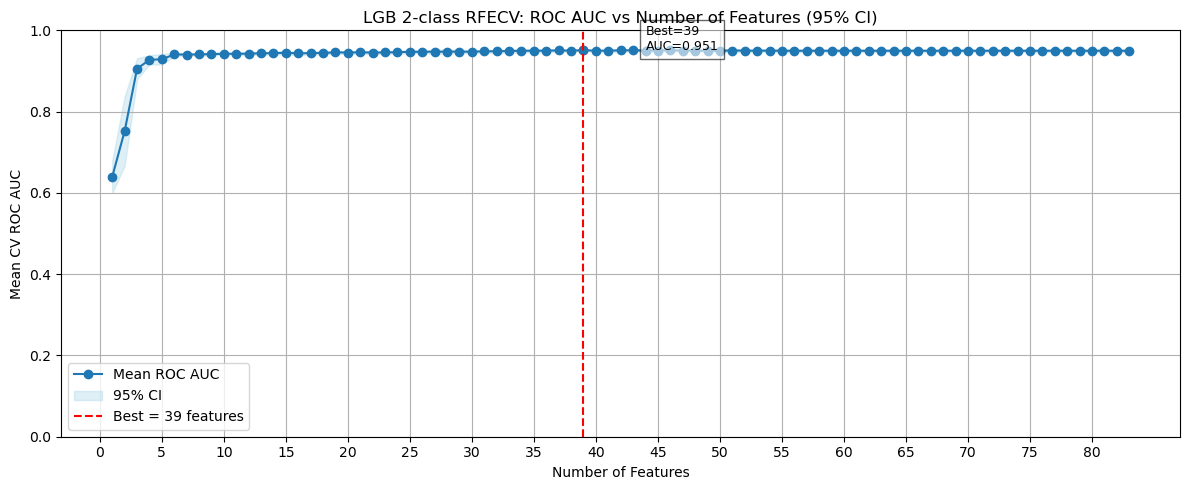

Fitting 5 folds for each of 128 candidates, totalling 640 fits
Best Parameters : {'learning_rate': 0.1, 'max_depth': 5, 'min_child_samples': 20, 'n_estimators': 200, 'num_leaves': 31, 'reg_alpha': 1, 'reg_lambda': 1}
Best CV ROC AUC : 0.951
Train ROC AUC   : 1.000

Calibrated prob range: [0.000, 1.000]
Mean prob (should be ~0.5): 0.507

Optimal threshold (Youden J on TEST set, calibrated): 0.4698
  Sensitivity (Pathogenic recall) : 0.870
  Specificity (Neutral recall) : 0.883


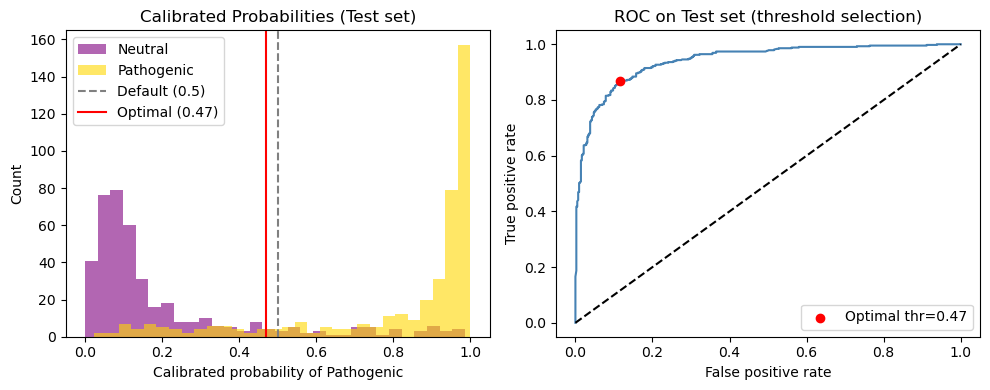


--- Test Set: Default threshold (0.5) ---


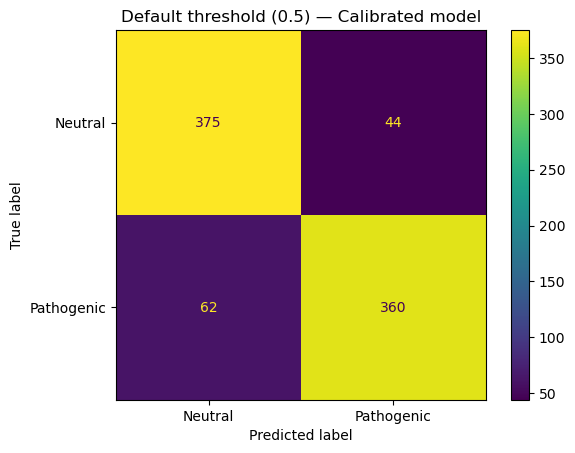

              precision    recall  f1-score   support

     Neutral       0.86      0.89      0.88       419
  Pathogenic       0.89      0.85      0.87       422

    accuracy                           0.87       841
   macro avg       0.87      0.87      0.87       841
weighted avg       0.87      0.87      0.87       841


--- Test Set: Optimal threshold (0.470) ---


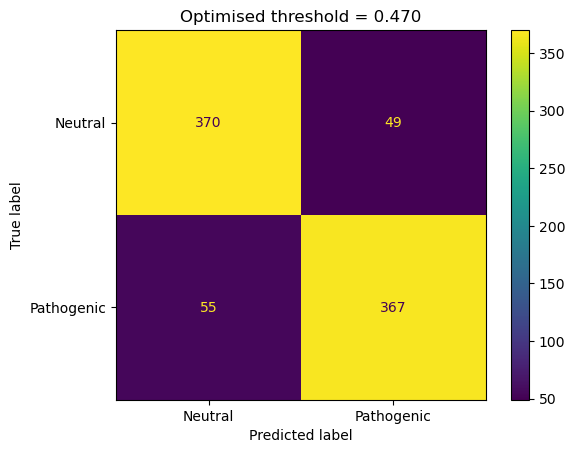

              precision    recall  f1-score   support

     Neutral       0.87      0.88      0.88       419
  Pathogenic       0.88      0.87      0.88       422

    accuracy                           0.88       841
   macro avg       0.88      0.88      0.88       841
weighted avg       0.88      0.88      0.88       841


★ LightGBM Validation AUC (calibrated): 0.8210


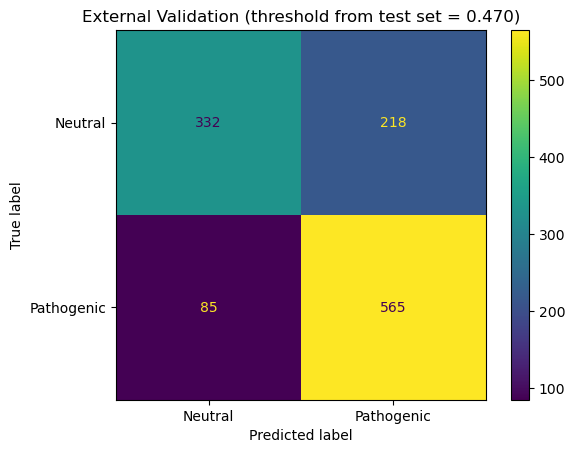

              precision    recall  f1-score   support

     Neutral       0.80      0.60      0.69       550
  Pathogenic       0.72      0.87      0.79       650

    accuracy                           0.75      1200
   macro avg       0.76      0.74      0.74      1200
weighted avg       0.76      0.75      0.74      1200


CV AUC: 0.949 ± 0.005


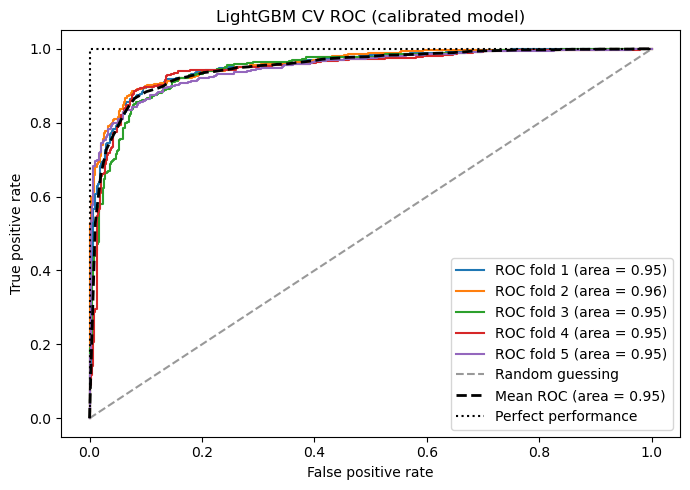

cv ROC AUC   : 0.932 ± 0.042
cv precision : 0.876 ± 0.047
cv recall    : 0.875 ± 0.047
cv f1        : 0.875 ± 0.047


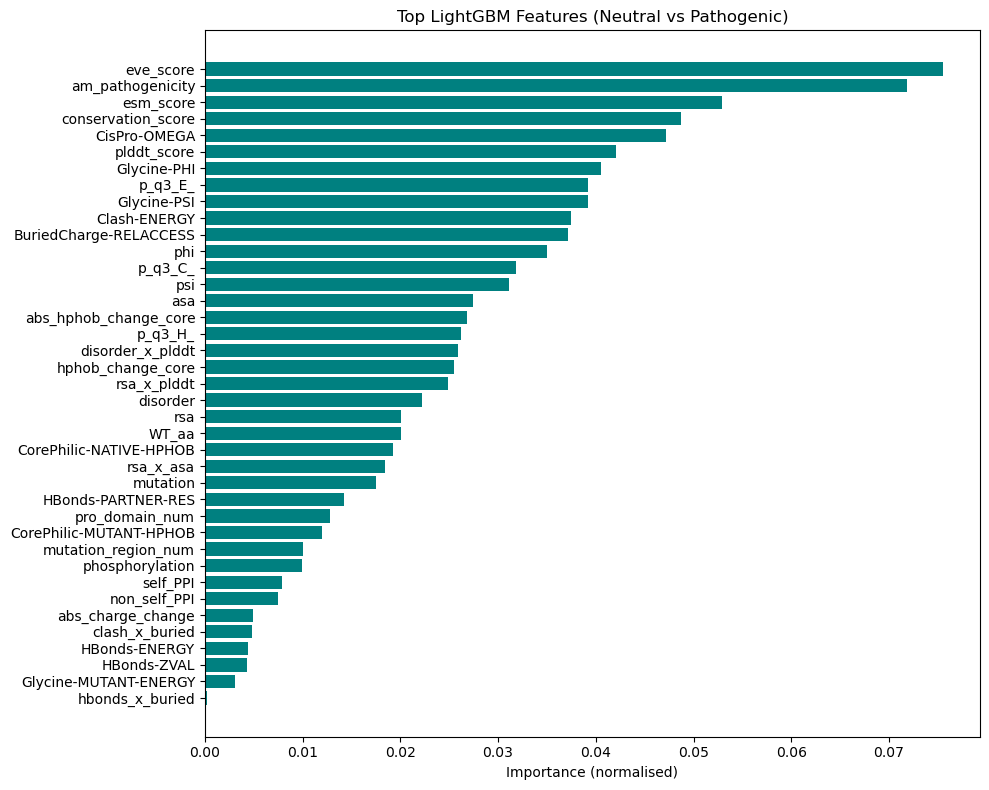


Top features:
           Feature  Importance
         eve_score    0.075540
  am_pathogenicity    0.071861
         esm_score    0.052906
conservation_score    0.048668
      CisPro-OMEGA    0.047224
       plddt_score    0.042101
       Glycine-PHI    0.040564
           p_q3_E_    0.039167
       Glycine-PSI    0.039167
      Clash-ENERGY    0.037491


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split, cross_val_score
from sklearn.feature_selection import RFECV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.base import clone
import pandas as pd

AUC, AUC_sd, AC, AC_sd, Pre, Pre_sd, Re, Re_sd, f1, f1_sd, Best1, Best2 = ([] for _ in range(12))


# ── 2. RFECV feature selection ────────────────────────────────────────────────
lgbm_rfe = lgb.LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)
rfecv_lgb = RFECV(
    estimator=lgbm_rfe,
    step=1,
    min_features_to_select=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc",
    n_jobs=-1,
)
rfecv_lgb.fit(X_train, Y_train)
lgb_features = list(rfecv_lgb.get_feature_names_out())
print(f"LGB optimal features: {rfecv_lgb.n_features_} → {lgb_features}")

X_train_selected = X_train[lgb_features]
X_test_selected  = X_test[lgb_features]

# plot RFECV curve with 95% CI
n_features  = len(rfecv_lgb.cv_results_["mean_test_score"])
mean_scores = rfecv_lgb.cv_results_["mean_test_score"]          
std_scores  = rfecv_lgb.cv_results_["std_test_score"]
ci          = 1.96 * (std_scores / np.sqrt(5))  # 95% confidence interval
x_range     = range(1, n_features + 1)
best_idx    = np.argmax(mean_scores)        # index of best score (max AUC)
plt.figure(figsize=(12, 5))
plt.plot(x_range, mean_scores, marker='o', label='Mean ROC AUC')
plt.fill_between(x_range, mean_scores - ci, mean_scores + ci,
                 color='lightblue', alpha=0.4, label='95% CI')
plt.axvline(best_idx + 1, color='red', linestyle='--',
            label=f'Best = {best_idx + 1} features')
plt.scatter(best_idx + 1, mean_scores[best_idx], color='red')
plt.text(best_idx + 1 + 5, mean_scores[best_idx],
         f'Best={best_idx+1}\nAUC={mean_scores[best_idx]:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))
plt.xlabel("Number of Features"); plt.ylabel("Mean CV ROC AUC") 
plt.title("LGB 2-class RFECV: ROC AUC vs Number of Features (95% CI)")
plt.xticks(np.arange(0, n_features + 1, step=5))
plt.ylim(0, 1); plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig("LGB_2class_RFECV_feature_selection.png", dpi=600)
plt.show()


# ── 3. GridSearch ─────────────────────────────────────────────────────────────
param_grid = {
    'n_estimators':  [100, 200],
    'max_depth':     [3, 5],
    'learning_rate': [0.1, 0.2],
    'num_leaves':    [31, 62],
    'reg_alpha':     [0.1, 1],
    'reg_lambda':    [0.1, 1],
    'min_child_samples': [10, 20]
}

gs = GridSearchCV(
    estimator=lgb.LGBMClassifier(random_state=42, verbose=-1, class_weight='balanced'),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    refit=True, n_jobs=-1, verbose=1, return_train_score=True
)
gs.fit(X_train_selected, Y_train)

best_params = gs.best_params_
print(f"Best Parameters : {best_params}")
print(f"Best CV ROC AUC : {gs.best_score_:.3f}")
print(f"Train ROC AUC   : {gs.cv_results_['mean_train_score'][gs.best_index_]:.3f}")

# ── 4. Calibrate probabilities ────────────────────────────────────────────────
raw_model_lgb = lgb.LGBMClassifier(**best_params, random_state=42, verbose=-1,
                                class_weight='balanced')
calibrated_model_lgb = CalibratedClassifierCV(raw_model_lgb, method='isotonic', cv=5)
calibrated_model_lgb.fit(X_train_selected, Y_train)

proba_test_cal = calibrated_model_lgb.predict_proba(X_test_selected)[:, 1]
print(f"\nCalibrated prob range: [{proba_test_cal.min():.3f}, {proba_test_cal.max():.3f}]")
print(f"Mean prob (should be ~0.5): {proba_test_cal.mean():.3f}")

# ── 5. Threshold search on TEST set (Youden-J) ───────────────────────────────
fpr_t, tpr_t, thr_t = roc_curve(Y_test, proba_test_cal, pos_label=1)
j_idx    = np.argmax(tpr_t - fpr_t)
best_thr = thr_t[j_idx]
print(f"\nOptimal threshold (Youden J on TEST set, calibrated): {best_thr:.4f}")
print(f"  Sensitivity (Pathogenic recall) : {tpr_t[j_idx]:.3f}")
print(f"  Specificity (Neutral recall) : {1 - fpr_t[j_idx]:.3f}")

# ── 6. Probability distribution plot (sanity check on TEST set) ──────────────
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(proba_test_cal[Y_test == 0], bins=30, alpha=0.6, label='Neutral', color='purple')
plt.hist(proba_test_cal[Y_test == 1], bins=30, alpha=0.6, label='Pathogenic', color='gold')
plt.axvline(0.5,      color='gray', linestyle='--', label='Default (0.5)')
plt.axvline(best_thr, color='red',  linestyle='-',  label=f'Optimal ({best_thr:.2f})')
plt.xlabel('Calibrated probability of Pathogenic')
plt.ylabel('Count')
plt.title('Calibrated Probabilities (Test set)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fpr_t, tpr_t, color='steelblue')
plt.scatter(fpr_t[j_idx], tpr_t[j_idx], color='red', zorder=5,
            label=f'Optimal thr={best_thr:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC on Test set (threshold selection)')
plt.legend()
plt.tight_layout()
plt.savefig("lgb_calibrated_threshold_analysis.png", dpi=600)
plt.show()

# ── 7. Apply optimal threshold to TEST set ────────────────────────────────────
print("\n--- Test Set: Default threshold (0.5) ---")
y_pred_default = (proba_test_cal >= 0.5).astype(int)
cm_def = confusion_matrix(Y_test, y_pred_default)
ConfusionMatrixDisplay(cm_def, display_labels=['Neutral', 'Pathogenic']).plot(cmap='viridis')
plt.title("Default threshold (0.5) — Calibrated model")
plt.savefig("lgb_bestModel_ConfusionMatrix_default_miRNA_HG.png", dpi=600)
plt.show()
print(classification_report(Y_test, y_pred_default, target_names=['Neutral', 'Pathogenic']))

print(f"\n--- Test Set: Optimal threshold ({best_thr:.3f}) ---")
y_pred_opt = (proba_test_cal >= best_thr).astype(int)
cm_opt = confusion_matrix(Y_test, y_pred_opt)
ConfusionMatrixDisplay(cm_opt, display_labels=['Neutral', 'Pathogenic']).plot(cmap='viridis')
plt.title(f"Optimised threshold = {best_thr:.3f}")
plt.savefig("lgb_bestModel_ConfusionMatrix_OptThr_miRNA_HG.png", dpi=600)
plt.show()
print(classification_report(Y_test, y_pred_opt, target_names=['Neutral', 'Pathogenic']))

# ── 8. External Validation (BLIND — threshold already fixed from test set) ────
lgb_val_fresh = test_val_df.copy()  # already preprocessed and ready for LGB

target_lgb    = lgb_val_fresh['goflof']
X_val_lgb     = lgb_val_fresh[lgb_features]
proba_val_cal = calibrated_model_lgb.predict_proba(X_val_lgb)[:, 1]

# AUC on external validation
auc_lgb_val = roc_auc_score(target_lgb, proba_val_cal)
print(f"\n★ LightGBM Validation AUC (calibrated): {auc_lgb_val:.4f}")

# Apply the threshold derived from TEST set — no leakage from validation
y_pred_val = (proba_val_cal >= best_thr).astype(int)
cm_val = confusion_matrix(target_lgb, y_pred_val)
ConfusionMatrixDisplay(cm_val, display_labels=['Neutral', 'Pathogenic']).plot(cmap='viridis')
plt.title(f"External Validation (threshold from test set = {best_thr:.3f})")
plt.savefig("lgb_bestModel_ConfusionMatrix_validation.png", dpi=600)
plt.show()
print(classification_report(target_lgb, y_pred_val, target_names=['Neutral', 'Pathogenic']))

# ── 9. CV ROC folds ───────────────────────────────────────────────────────────
cv_outer = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train_selected, Y_train))
mean_tpr = np.zeros(100)
mean_fpr = np.linspace(0, 1, 100)
sd_list  = []

plt.figure(figsize=(7, 5))
for i, (tr, te) in enumerate(cv_outer):
    fold_model = lgb.LGBMClassifier(**best_params, random_state=42, verbose=-1,
                                     class_weight='balanced')
    fold_model.fit(X_train_selected.iloc[tr], Y_train.iloc[tr])
    probas      = fold_model.predict_proba(X_train_selected.iloc[te])
    fpr, tpr, _ = roc_curve(Y_train.iloc[te], probas[:, 1], pos_label=1)
    mean_tpr   += np.interp(mean_fpr, fpr, tpr)
    fold_auc    = auc(fpr, tpr)
    sd_list.append(fold_auc)
    plt.plot(fpr, tpr, label=f'ROC fold {i+1} (area = {fold_auc:.2f})')

mean_tpr /= len(cv_outer)
mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
mean_sd  = np.std(sd_list)
print(f"\nCV AUC: {mean_auc:.3f} ± {mean_sd:.3f}")

plt.plot([0, 1],    [0, 1],    linestyle='--', color=(.6,.6,.6), label='Random guessing')
plt.plot(mean_fpr,  mean_tpr,  'k--', lw=2,   label=f'Mean ROC (area = {mean_auc:.2f})')
plt.plot([0, 0, 1], [0, 1, 1], linestyle=':',  color='black',   label='Perfect performance')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('LightGBM CV ROC (calibrated model)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("lgb_bestModel_AUC_miRNA_HG.png", dpi=600)
plt.show()

AUC.append(mean_auc)
AUC_sd.append(mean_sd)

# ── 10. CV metrics ────────────────────────────────────────────────────────────
fresh_lgb = lgb.LGBMClassifier(**best_params, random_state=42, verbose=-1,
                                 class_weight='balanced')
scores1 = cross_val_score(fresh_lgb, X_train_selected, Y_train, scoring='roc_auc', cv=5)
scores2 = cross_val_score(fresh_lgb, X_train_selected, Y_train,
                          scoring=make_scorer(precision_score, average='macro'), cv=5)
scores3 = cross_val_score(fresh_lgb, X_train_selected, Y_train,
                          scoring=make_scorer(recall_score,    average='macro'), cv=5)
scores4 = cross_val_score(fresh_lgb, X_train_selected, Y_train,
                          scoring=make_scorer(f1_score,        average='macro'), cv=5)

print(f"cv ROC AUC   : {np.mean(scores1):.3f} ± {np.std(scores1):.3f}")
print(f"cv precision : {np.mean(scores2):.3f} ± {np.std(scores2):.3f}")
print(f"cv recall    : {np.mean(scores3):.3f} ± {np.std(scores3):.3f}")
print(f"cv f1        : {np.mean(scores4):.3f} ± {np.std(scores4):.3f}")

AC.append(np.mean(scores1));  AC_sd.append(np.std(scores1))
Pre.append(np.mean(scores2)); Pre_sd.append(np.std(scores2))
Re.append(np.mean(scores3));  Re_sd.append(np.std(scores3))
f1.append(np.mean(scores4));  f1_sd.append(np.std(scores4))
Best1.append(best_params['n_estimators'])
Best2.append(best_params['num_leaves'])

# -─ 11. Feature importance (Gain) ─────────────────────────────────────────────
importances_list = []
for calibrated_clf in calibrated_model_lgb.calibrated_classifiers_:         
    importances_list.append(calibrated_clf.estimator.feature_importances_)
importances = np.mean(importances_list, axis=0)
importances = importances / importances.sum()   # normalise to 0–1      
feature_importance_df = pd.DataFrame({'Feature': X_train_selected.columns, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
n_top = min(52, len(feature_importance_df))
plt.figure(figsize=(10, 8))
plt.barh(
    feature_importance_df['Feature'][:n_top][::-1],
    feature_importance_df['Importance'][:n_top][::-1],
    color='teal'
)
plt.xlabel('Importance (normalised)')
plt.title('Top LightGBM Features (Neutral vs Pathogenic)')
plt.tight_layout()
plt.savefig("lgb_bestModel_FeatureImportance_miRNA_HG.png", dpi=600)
plt.show()  
print("\nTop features:")
print(feature_importance_df.head(10).to_string(index=False))

# model and feature importance to CSV
import joblib
joblib.dump(calibrated_model_lgb, "lgb_pathogenicity.pkl")
feature_importance_df.to_csv("lgb_pathogenicity-features.csv", index=False)


Feature Importance